# 7 - Forest Plots

**Purpose**: Covariate comparison forest plots (None vs TMB/Clinical/Purity)
for OS, PFS, BOR, and DCB across broad tumour-type cohorts and ICI treatment
mechanisms. Both panels use the same forest plot functions — only the grouping
column differs (cohort vs mechanism).

| | |
|---|---|
| **Inputs** | `models_ready.rds` (unified: cohort + mechanism rows) |
| **Outputs** | `figs/supplement_forest.rds/.png` (A/B: tumour-type, C/D: mechanism) |
| **Run after** | `0_prepare/5_models.ipynb` |


In [1]:
source(paste0(dirname(getwd()), "/helpers/map.r"))
source(paste0(dirname(getwd()), "/helpers/shortcuts.r"))
source(paste0(dirname(getwd()), "/helpers/config.r"))
source(paste0(dirname(getwd()), "/helpers/themes.r"))

dir.create(paste0(CIDER_PROJ_DIR, "figs/"), showWarnings = FALSE, recursive = TRUE)

In [2]:
library(ggpubr)
library(patchwork)

# 0 - Read model results

In [3]:
results <- readRDS(paste0(CIDER_PROJ_DIR, "models_ready.rds"))

# ── Backfill strata columns for files generated before unified schema ──────
if (!"strata_type" %in% names(results)) {
  message("models_ready.rds predates unified schema — backfilling strata columns")
  results <- results |>
    dplyr::mutate(
      strata      = cohort_broad_go,
      strata_type = "cohort"
    )
}
if (!"metric_type" %in% names(results)) {
  message("models_ready.rds missing metric_type — backfilling as CIDER Score")
  results <- dplyr::mutate(results, metric_type = "CIDER Score")
}


# 1 - Figure functions

In [ ]:
# ── Shared palettes ───────────────────────────────────────────────────────────
# covariate_colors: 2-level, non-Responder-like contrast (rule 3) between
# an unadjusted model ("None", baseline -> COL_NEGATIVE) and the fully
# adjusted model ("TMB/Clinical/Purity" -> COL_ACCENT; not COL_POSITIVE,
# since "adjusted" isn't inherently a positive outcome, just a different
# covariate spec).
covariate_colors <- c(
  "None"                = COL_NEGATIVE,
  "TMB/Clinical/Purity" = COL_ACCENT
)

# endpoint_colors (OS/PFS/BOR/DCB) is now the shared constant defined once
# in helpers/themes.r (already sourced above) -- no local redefinition here,
# so this notebook's forest plots stay in sync with every other
# endpoint-coloured panel in the paper.

# ── Covariate comparison: OS + PFS (Cox-PH) ───────────────────────────────────
# group_col        : column name (string) to use as facet columns
# strip_labeller   : ggplot2 labeller; defaults to renaming "ICI-Treated" → "All ICI"
forest_comparison <- function(data, group_col, x_lab, title,
                              strip_labeller = NULL, clip = NULL) {
  if (is.null(strip_labeller)) {
    strip_labeller <- ggplot2::labeller(
      .cols = function(x) sub("ICI-Treated", "All ICI", x)
    )
  }
  data |>
    dplyr::filter(model == "Cox-PH", term == "cider_log2",
                  metric_type == "CIDER Score",
                  endpoint %in% c("OS", "PFS"),
                  covariates %in% c("None", "TMB/Clinical/Purity",
                                    "TMB + Clinical + Purity")) |>
    dplyr::filter(grepl("T-cell", gp)) |>
    dplyr::mutate(
      covariates      = dplyr::recode(covariates,
                          "TMB + Clinical + Purity" = "TMB/Clinical/Purity"),
      covariates      = factor(covariates, levels = c("TMB/Clinical/Purity", "None")),
      endpoint        = factor(endpoint, levels = c("PFS", "OS")),
      gp              = factor(gp, levels = rev(GP_LEVELS[grepl("T-cell", GP_LEVELS)])),
      ci_crosses_zero = dplyr::coalesce(conf.low < 0 & conf.high > 0, TRUE),
      conf.low        = if (!is.null(clip)) pmax(conf.low,  -clip) else conf.low,
      conf.high       = if (!is.null(clip)) pmin(conf.high,  clip) else conf.high,
      estimate        = if (!is.null(clip)) pmax(pmin(estimate, clip), -clip) else estimate
    ) |>
    ggplot2::ggplot(ggplot2::aes(
      x = estimate, y = gp,
      colour = endpoint, shape = covariates, alpha = ci_crosses_zero
    )) +
    ggplot2::geom_vline(xintercept = 0, linetype = "dashed", colour = COL_NEGATIVE) +
    ggplot2::geom_pointrange(
      ggplot2::aes(xmin = conf.low, xmax = conf.high),
      size = 0.6, fatten = 3,
      position = ggplot2::position_dodge(width = 0.6)
    ) +
    ggplot2::scale_colour_manual(values = endpoint_colors, name = "Survival Endpoint") +
    ggplot2::scale_shape_manual(
      values = c("None" = 16, "TMB/Clinical/Purity" = 17),
      name   = "Covariates"
    ) +
    ggplot2::scale_alpha_manual(
      values      = c("FALSE" = 1.0, "TRUE" = 0.25),
      labels      = c("FALSE" = "p < 0.05", "TRUE" = "p ≥ 0.05"),
      name        = "Significance",
      na.translate = FALSE
    ) +
    ggplot2::scale_x_continuous(n.breaks = 3) +
    ggplot2::guides(
      colour = ggplot2::guide_legend(ncol = 1, reverse = TRUE, order = 3),
      shape  = ggplot2::guide_legend(ncol = 1, reverse = TRUE, order = 2),
      alpha  = ggplot2::guide_legend(ncol = 1, order = 4)
    ) +
    ggplot2::facet_grid(
      cols     = ggplot2::vars(.data[[group_col]]),
      scales   = "free_x",
      labeller = strip_labeller
    ) +
    go_theme +
    ggplot2::theme(
      axis.text.y           = ggplot2::element_text(size = 7),
      axis.text.x           = ggplot2::element_text(size = 6),
      strip.text.x          = ggplot2::element_text(size = 6),
      legend.text           = ggplot2::element_text(size = 6),
      legend.title          = ggplot2::element_text(size = 7, face = "bold"),
      legend.key.size       = ggplot2::unit(0.35, "cm"),
      legend.position       = "bottom",
      legend.title.position = "top"
    ) +
    ggplot2::labs(x = x_lab, y = NULL, title = title)
}

# ── Covariate comparison: BOR + DCB (logistic regression) ─────────────────────
forest_comparison_response <- function(data, group_col, x_lab, title,
                                       strip_labeller = NULL, clip = NULL) {
  if (is.null(strip_labeller)) {
    strip_labeller <- ggplot2::labeller(
      .cols = function(x) sub("ICI-Treated", "All ICI", x)
    )
  }
  data |>
    dplyr::filter(model == "Logistic Regression", term == "cider_log2",
                  metric_type == "CIDER Score",
                  endpoint %in% c("BOR", "DCB"),
                  covariates %in% c("None", "TMB/Clinical/Purity",
                                    "TMB + Clinical + Purity")) |>
    dplyr::filter(grepl("T-cell", gp)) |>
    dplyr::mutate(
      covariates      = dplyr::recode(covariates,
                          "TMB + Clinical + Purity" = "TMB/Clinical/Purity"),
      covariates      = factor(covariates, levels = c("TMB/Clinical/Purity", "None")),
      endpoint        = factor(endpoint, levels = c("DCB", "BOR")),
      gp              = factor(gp, levels = rev(GP_LEVELS[grepl("T-cell", GP_LEVELS)])),
      ci_crosses_zero = dplyr::coalesce(conf.low < 0 & conf.high > 0, TRUE),
      conf.low        = if (!is.null(clip)) pmax(conf.low,  -clip) else conf.low,
      conf.high       = if (!is.null(clip)) pmin(conf.high,  clip) else conf.high,
      estimate        = if (!is.null(clip)) pmax(pmin(estimate, clip), -clip) else estimate
    ) |>
    ggplot2::ggplot(ggplot2::aes(
      x = estimate, y = gp,
      colour = endpoint, shape = covariates, alpha = ci_crosses_zero
    )) +
    ggplot2::geom_vline(xintercept = 0, linetype = "dashed", colour = COL_NEGATIVE) +
    ggplot2::geom_pointrange(
      ggplot2::aes(xmin = conf.low, xmax = conf.high),
      size = 0.6, fatten = 3,
      position = ggplot2::position_dodge(width = 0.6)
    ) +
    ggplot2::scale_colour_manual(values = endpoint_colors, name = "RECIST Endpoint") +
    ggplot2::scale_shape_manual(
      values = c("None" = 16, "TMB/Clinical/Purity" = 17),
      name   = "Covariates"
    ) +
    ggplot2::scale_alpha_manual(
      values      = c("FALSE" = 1.0, "TRUE" = 0.25),
      labels      = c("FALSE" = "p < 0.05", "TRUE" = "p ≥ 0.05"),
      name        = "Significance",
      na.translate = FALSE
    ) +
    ggplot2::scale_x_continuous(n.breaks = 3) +
    ggplot2::guides(
      colour = ggplot2::guide_legend(ncol = 1, reverse = TRUE, order = 1),
      shape  = ggplot2::guide_legend(ncol = 1, reverse = TRUE, order = 2),
      alpha  = ggplot2::guide_legend(ncol = 1, order = 4)
    ) +
    ggplot2::facet_grid(
      cols     = ggplot2::vars(.data[[group_col]]),
      scales   = "free_x",
      labeller = strip_labeller
    ) +
    go_theme +
    ggplot2::theme(
      axis.text.y           = ggplot2::element_text(size = 7),
      axis.text.x           = ggplot2::element_text(size = 6),
      strip.text.x          = ggplot2::element_text(size = 6),
      legend.text           = ggplot2::element_text(size = 6),
      legend.title          = ggplot2::element_text(size = 7, face = "bold"),
      legend.key.size       = ggplot2::unit(0.35, "cm"),
      legend.position       = "bottom",
      legend.title.position = "top"
    ) +
    ggplot2::labs(x = x_lab, y = NULL, title = title)
}


# 4 - Covariate comparison: robustness to TMB/Clinical/Purity adjustment

Compares CIDER Score effect size between two model specifications:
unadjusted (None) and fully adjusted (TMB/Clinical/Purity). Robustness
of the point estimate across rows is evidence the signal is not driven
by TMB, purity, or clinical covariates.

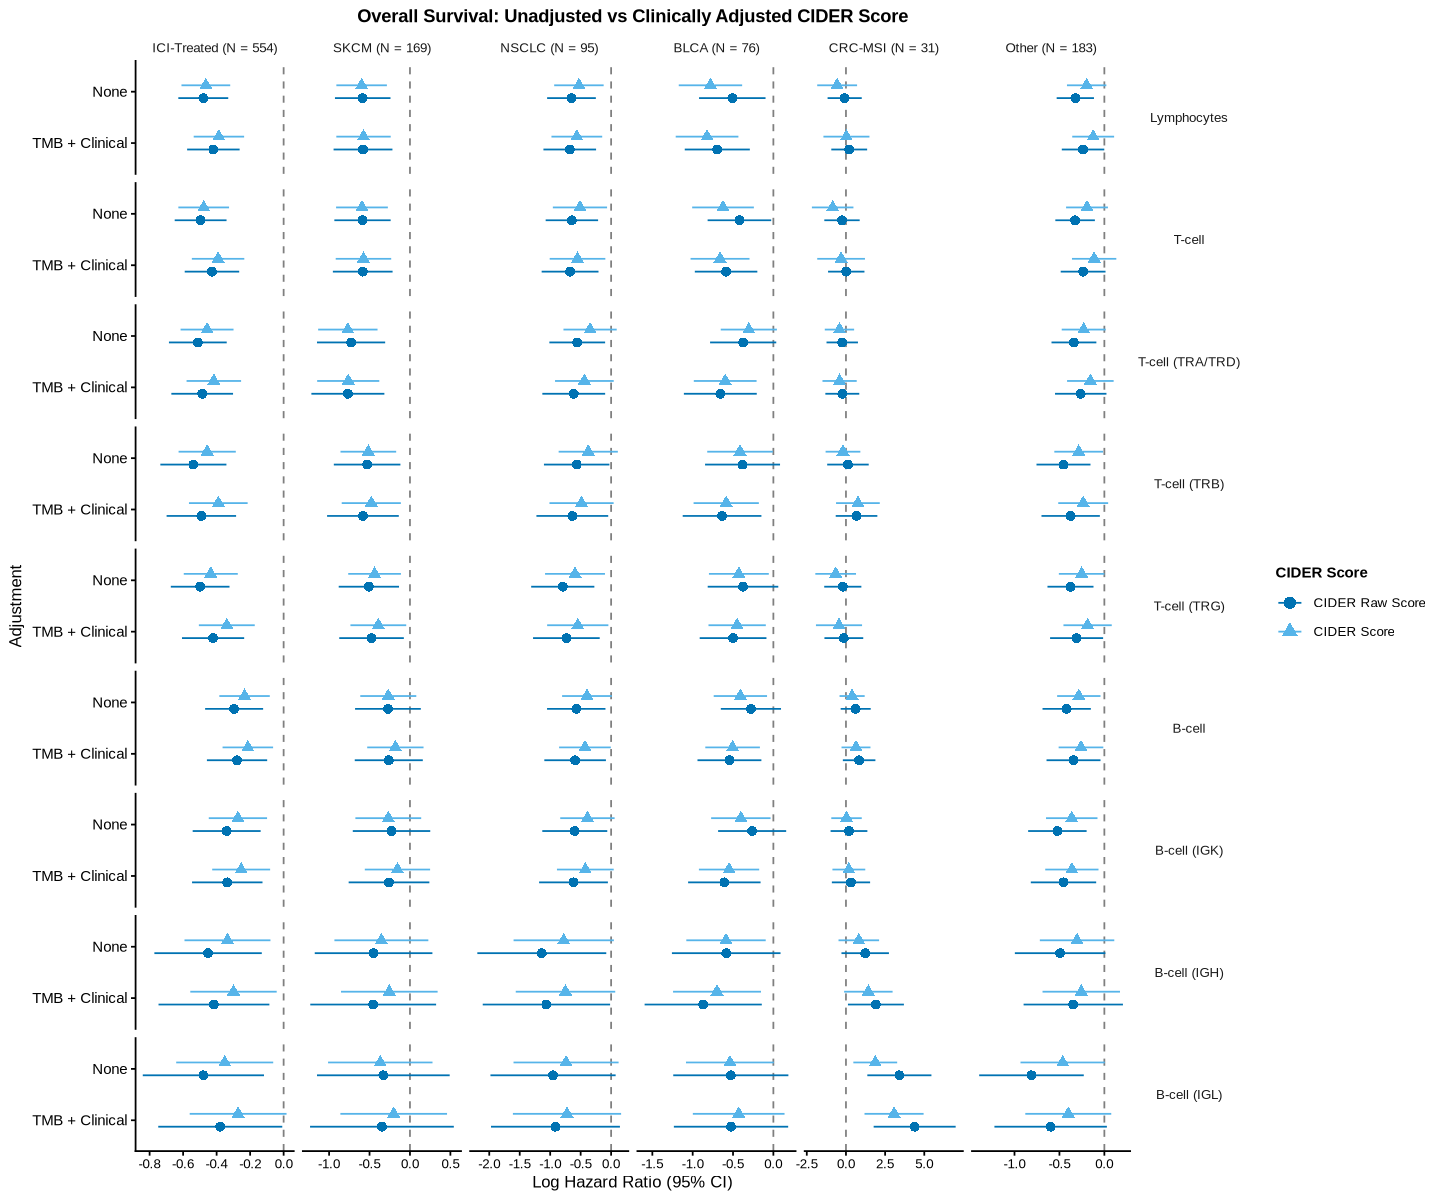

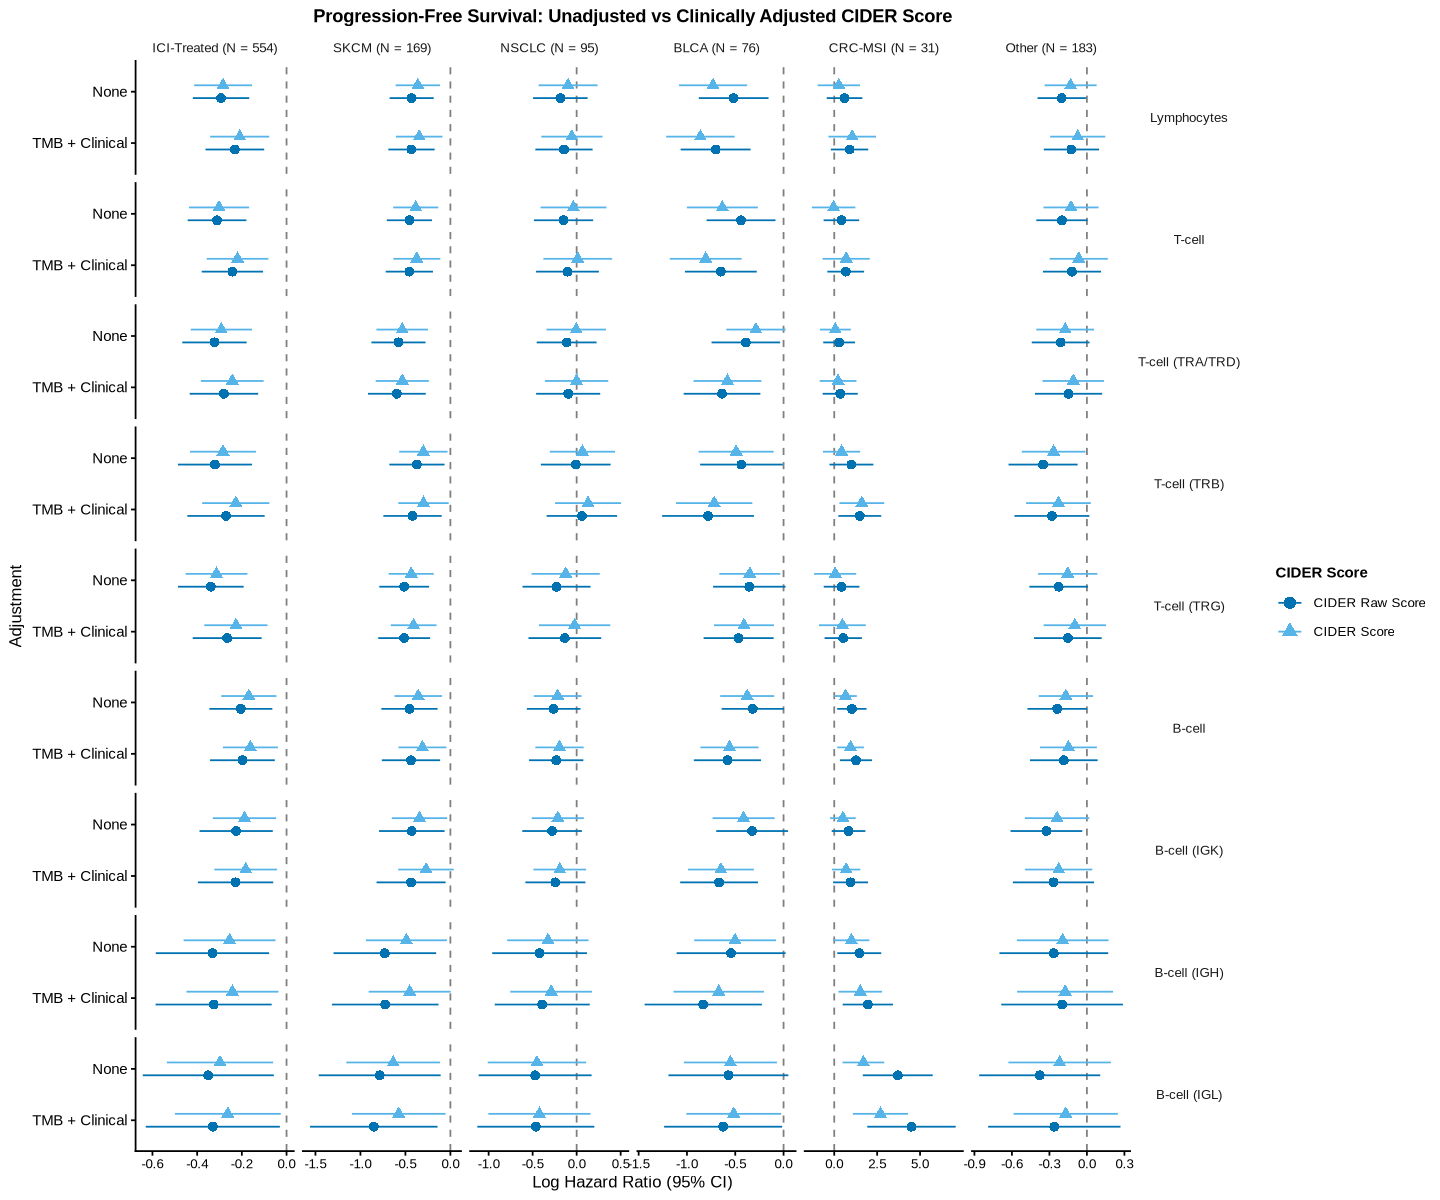

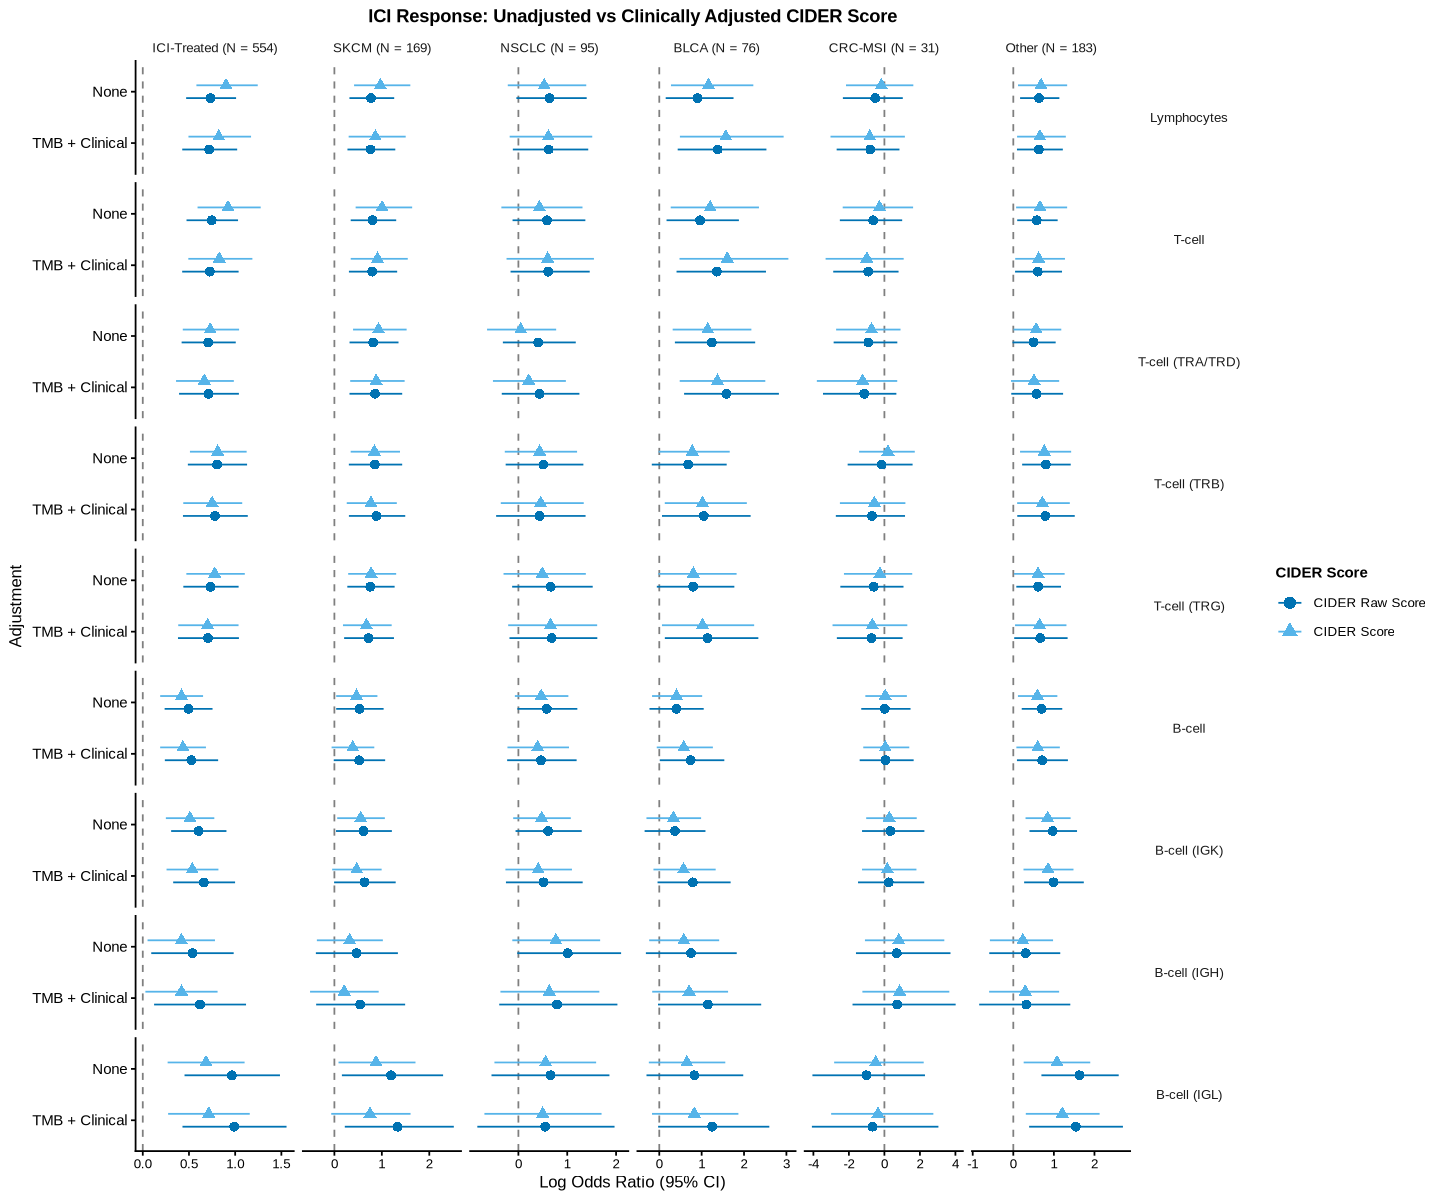

In [5]:
# ── Tumour-type covariate comparison ─────────────────────────────────────────
cohort_data <- dplyr::filter(results, strata_type == "cohort")

comparison_os_pfs <- forest_comparison(
  cohort_data, "strata",
  x_lab = "Better Survival ← Log Hazard Ratio (95% CI) → Worse Survival",
  title = "CIDER Score vs OS and PFS by Tumor Type"
)
set_plot_dims(12, 10); comparison_os_pfs

comparison_response <- forest_comparison_response(
  cohort_data, "strata",
  x_lab = "Less Response ← Log Odds Ratio (95% CI) → More Response",
  title = "CIDER Score vs BOR and DCB by Tumor Type"
)
set_plot_dims(12, 10); comparison_response


In [ ]:
# ── Combined forest figure: Response/DCB (A) + OS/PFS (B) ──────────────────
# Panel A: logistic regression (Response + DCB)
# Panel B: Cox-PH (OS + PFS)
# Strip labels suppressed on B to avoid repetition.
# Guides collected into a single right-side legend.
comparison_forest_combined <-
  (comparison_response /
   comparison_os_pfs) +
  plot_layout(heights = c(1, 1), guides = "collect") +
  figure_annotation(legend_pos = "right")

set_plot_dims(9, 10); comparison_forest_combined

# 2 - Mechanism subgroup forest plots

Same functions as the tumour-type section above; mechanism rows are
pre-filtered from the unified `results` object using `strata_type == "mechanism"`.


In [ ]:
# ── Mechanism data ────────────────────────────────────────────────────────────
# Strata levels are derived from whatever `mechanism` strata values
# 5_models.ipynb actually produced (mech_ready's mechanism_group there is
# built via fct_pin_last(factor(mechanism), "Multiple mechanism") -- the
# same call Table S5/Table 1 use), NOT a hand-typed whitelist. A hand-typed
# whitelist here previously assumed exact literal spellings ("Anti-PDL1",
# "Anti-CTLA4") that don't match the real clinical_go.txt strings now that
# 5_models.ipynb reads `mechanism` straight from cpi_ready.rds -- any row
# whose real value didn't byte-for-byte match the guessed whitelist became
# NA at the factor(strata, levels = <whitelist>) step below and silently
# vanished from the plot (this is what dropped "Anti-CTLA4" and "Anti-PDL1").
# Deriving the levels from the data instead removes that whole class of
# mismatch. "Anti-CTLA4/Anti-PD1" -> "Anti-CTLA4/PD1" is still a literal
# recode because that string IS one we control directly (the
# Ipilimumab/Nivolumab override in 3_meta.ipynb), so shortening it for the
# axis label is safe.
mechanism_strata_observed <- results |>
  dplyr::filter(strata_type == "mechanism") |>
  dplyr::pull(strata) |>
  as.character() |>
  unique() |>
  dplyr::recode("Anti-CTLA4/Anti-PD1" = "Anti-CTLA4/PD1")

# Order strata by sample size (largest first, left to right in the facet),
# using N from one fixed, well-defined model spec (OS / None / T-cell /
# CIDER Score) -- the same spec mech_n_lookup below uses for the "(N = X)"
# labels -- so the ordering reflects real patient counts rather than a proxy
# like row-frequency across every fitted spec (which doesn't track N when
# specs drop different strata for different reasons, and is what silently
# scrambled this ordering previously). A stratum missing from that specific
# spec (e.g. dropped by the <10-obs floor for Cox but still fit for
# logistic) falls back to N = 0 for ordering purposes only -- it's still
# kept in MECHANISM_STRATA_LEVELS via mechanism_strata_observed above, so it
# can't silently disappear from the plot the way the earlier whitelist bug did.
mechanism_n_for_order <- results |>
  dplyr::filter(strata_type == "mechanism", endpoint == "OS", covariates == "None",
                gp == "T-cell", metric_type == "CIDER Score") |>
  dplyr::mutate(strata = dplyr::recode(as.character(strata), "Anti-CTLA4/Anti-PD1" = "Anti-CTLA4/PD1")) |>
  dplyr::distinct(strata, n_obs) |>
  tibble::deframe()

mechanism_order <- mechanism_strata_observed[
  order(-dplyr::coalesce(mechanism_n_for_order[mechanism_strata_observed], 0))
]

MECHANISM_STRATA_LEVELS <- c("All ICI", mechanism_order)
message("Mechanism strata levels, ordered by N (largest first): ",
        paste(MECHANISM_STRATA_LEVELS, collapse = ", "))

# ICI-Overall: pull ICI-Treated rows from cohort results and relabel as "All ICI"
ici_overall <- results |>
  dplyr::filter(strata_type == "cohort", grepl("ICI-Treated", strata),
                metric_type == "CIDER Score") |>
  dplyr::mutate(strata = "All ICI", strata_type = "mechanism")

mech_data <- dplyr::bind_rows(
    results |> dplyr::filter(strata_type == "mechanism"),
    ici_overall
  ) |>
  dplyr::mutate(
    strata = dplyr::recode(strata, "Anti-CTLA4/Anti-PD1" = "Anti-CTLA4/PD1"),
    strata = factor(strata, levels = MECHANISM_STRATA_LEVELS),
    gp     = factor(gp, levels = GP_LEVELS)
  )

# N per mechanism from OS / None / T-cell
mech_n_lookup <- mech_data |>
  dplyr::filter(endpoint == "OS", covariates == "None",
                gp == "T-cell", metric_type == "CIDER Score") |>
  dplyr::select(strata, n_obs) |>
  tibble::deframe()

# Append (N = X) to strata labels
s    <- as.character(MECHANISM_STRATA_LEVELS)
n    <- mech_n_lookup[s]
# Use a line break before (N = X) only for wide labels
sep  <- dplyr::if_else(nchar(s) > 12, "\n", " ")
lvls <- dplyr::if_else(!is.na(n), paste0(s, sep, "(N = ", n, ")"), s)

mech_data <- mech_data |>
  dplyr::mutate(
    strata = factor(
      dplyr::if_else(!is.na(mech_n_lookup[as.character(strata)]),
                     dplyr::if_else(
                       nchar(as.character(strata)) > 12,
                       paste0(as.character(strata), "\n(N = ", mech_n_lookup[as.character(strata)], ")"),
                       paste0(as.character(strata), " (N = ", mech_n_lookup[as.character(strata)], ")")
                     ),
                     as.character(strata)),
      levels = lvls
    )
  )


In [ ]:
# ── Mechanism subgroup forest plots ───────────────────────────────────────────
# clip = 10 caps CI whiskers at ±10 per panel while keeping scales free.
mech_os_pfs <- forest_comparison(
  mech_data, "strata",
  x_lab = "Better Survival ← Log Hazard Ratio (95% CI) → Worse Survival",
  title = "CIDER Score vs OS and PFS by ICI Mechanism",
  clip  = 10
)
set_plot_dims(10, 9); mech_os_pfs

mech_bor_dcb <- forest_comparison_response(
  mech_data, "strata",
  x_lab = "Less Response ← Log Odds Ratio (95% CI) → More Response",
  title = "CIDER Score vs BOR and DCB by ICI Mechanism",
  clip  = 10
)
set_plot_dims(10, 9); mech_bor_dcb


In [ ]:
# ── Combined mechanism figure: Response (A) + Survival (B) ───────────────────
mechanism_forest_combined <-
  (mech_bor_dcb /
   mech_os_pfs) +
  patchwork::plot_layout(heights = c(1, 1), guides = "collect") +
  figure_annotation(legend_pos = "right")

set_plot_dims(9, 10); mechanism_forest_combined



In [ ]:
# ── Combined A/B/C/D forest figure: response (A+B) / survival (C+D) ──────────
# Single shared legend on the right.
# A: tumour-type response (BOR/DCB)   B: mechanism response (BOR/DCB)
# C: tumour-type survival (OS/PFS)    D: mechanism survival (OS/PFS)
supplement_forest <-
  (comparison_response /
   mech_bor_dcb /
   comparison_os_pfs /
   mech_os_pfs) +
  patchwork::plot_layout(guides = "collect", heights = c(1, 1, 1, 1)) +
  figure_annotation(legend_pos = "right")

set_plot_dims(9.4, 11.7); supplement_forest

saveRDS(supplement_forest,
        paste0(CIDER_PROJ_DIR, "figs/supplement_forest.rds"))
ggsave(paste0(CIDER_PROJ_DIR, "figs/supplement_forest.png"),
       supplement_forest, width = 9.4, height = 11.7, dpi = 300)
message("Saved supplement_forest.png")
